**Ecuaciones Algebraicas No Lineales.**

Resolver ecuaciones trascendentales (que contienen términos exponenciales o logaritmicos, por ejemplo) no es tan bonito. Incluso podrían no tener soluciones analíticas, conviene desarrollar estrategias para resolverlas, al menos, de manera numérica.

## Método de Relajación

Una primera idea resulta del siguiente ejemplo: $x=2-e^x$.

Uno puede intentar por calcular los siguientes términos: $x_n = 2-e^{x_{n-1}}$, tal que si $n \rightarrow ∞$, $x_n$ tenderá a ser el número que resuelva la ecuación. No tengo idea de por qué, pero podemos intentarlos.

In [26]:
import numpy as np
xn = 0

for i in range(10000):
  xn = 2-np.exp(xn)


In [27]:
2-np.exp(xn)

np.float64(1.9952717555685402)

In [28]:
xn

np.float64(-5.354201301513358)

Uno ve que, en primera instancia. No se llega a nada. Pero que tal si expresamos la misma ecuación como sigue: $x = ln(2-x)$. Notar que aquí, x no puede ser dos

In [43]:
import numpy as np
xn = 0

for i in range(100):
  xn = np.log(2-xn)

In [44]:
xn

np.float64(0.4428544010023885)

In [45]:
np.log(2-xn)

np.float64(0.44285440100238865)

In [46]:
xn - (2-np.exp(xn))

np.float64(-2.220446049250313e-16)

Esta vez funcionó, y bastante rápido (bastaron 10 iteraciones), ¿por qué? Pensamiento: ¿tendrá algo que ver la condición que impone el logaritmo?

Probemos otro ejemplo: $x = 2-e^{-x}$. Esta ecuación tiene dos soluciones, cada una se puede obtener con las dos versiones de las ecuaciones, como se ve a continuación.

In [47]:
import matplotlib.pyplot as plt

In [57]:
def f1(x):
  return 2-np.exp(-x)
def f2(x):
  return -np.log(2-x)

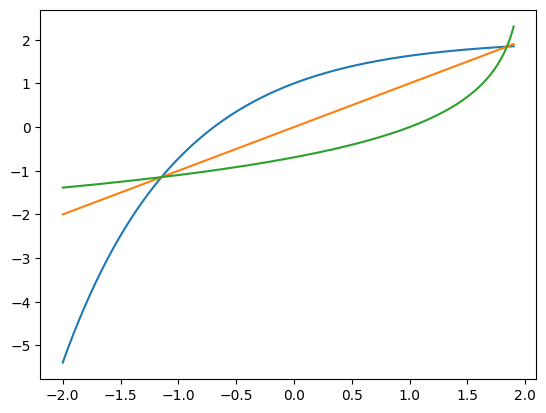

In [52]:
X = np.linspace(-2,1.9,1000)
Y = f1(X)
plt.plot(X,Y)
plt.plot(X,X)
plt.plot(X,f2(X))

In [62]:
xn=0
for i in range(100):
  xn = f1(xn)

In [63]:
xn

np.float64(1.8414056604369606)

In [64]:
xn=0
for i in range(100):
  xn = f2(xn)

In [65]:
xn

np.float64(-1.1461932206205825)

¿Por qué?

Considérese: $x_{n+1} = f(x)$ la serie a iterar. Supongamos por ahora que converge a un valor $x^*$ y expandamos en serie de Taylor alrededor de este punto:

$x_{n+1} \simeq f(x^*) + (x-x^*)f'(x^*) + \frac{(x-x^*)^2}{2!}f''(x^*) + \dots$

Por definición, $x^* = f(x^*)$. Quedémonos hasta el término lineal nada más, sustituimos y obtenemos:

$x_{n+1} - x^* = (x-x^*)f'(x^*) $

Esta ecuación lleva a concluir que la convergencia solo puede ocurrir si y solo si $|f'(x^*)| < 1$


Yo le creo al profe, pero esto todavía no explica por qué a veces sí salen y a veces no. Además, ¿cómo saber cuantos valores de x cumplen las ecuaciones?

Idea1: Las derivadas en el ejemplo pueden llegar a ser bastante diferentes entre sí. Quizá es por eso. Sí, probablemente es por eso.

Sí, es por eso (vimos un ejemplo, pero no pienso anotarlo yujuuuuuuu).

Para ecuaciones con más de una solución, la solución que obtendremos dependerá de la condición inicial. Se podrían probar varios para investigar (ayudarse graficando quizá sería útil)

Ejercicio. Usar el método de relajación (¿por qué se llama así? wwwwwwwwwwww) para la función $x = \frac{1}{2}sin^{-1}(x-x^2)$

In [68]:
def f(x):
  return 0.5*np.arcsin(x-x**2)

xn=0.67
for i in range(100):
  xn = f(xn)

/tmp/ipykernel_1373/200068115.py:2: RuntimeWarning: invalid value encountered in arcsin
  return 0.5*np.arcsin(x-x**2)


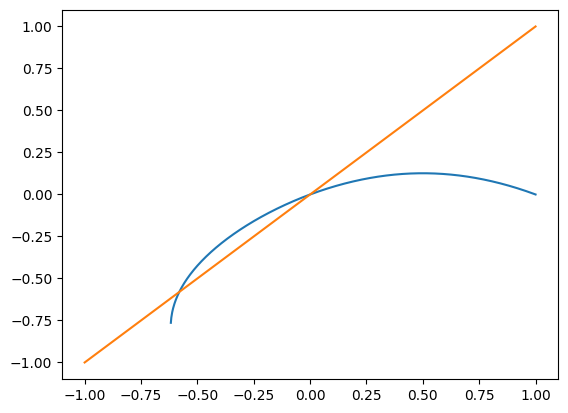

In [76]:
X = np.linspace(-1,1,1000)
Y = f(X)
plt.plot(X,Y)
plt.plot(X,X)

In [77]:
xn #parece que sí es. Pero hay más, intentaré sacar la otra

np.float64(1.420258466904545e-31)

In [86]:
def F(x):
  return x**2 + np.sin(2*x)

In [93]:
xn=-0.5
for i in range(100):
  xn = F(xn)

In [94]:
xn

np.float64(-0.5802959335950271)

Tendremos un error $\epsilon$ asociado al método que cumple la siguiente relación:

$\epsilon_{n+1} = \epsilon_n f'(x^*)$.

Con esto:

$x^* = x_n + \frac{\epsilon_{n+1}}{f'(x^*)}$ Es decir, el resultado numérico más una correción $\epsilon_n$.

También podemos tomar el siguiente término con su respectivo error: $x^* = x_{n+1} + \epsilon_{n+1}$, lo que conduce hasta:

$\epsilon_{n+1} = \frac{x_n-x_{n+1}}{1-1/f'(x^*)}$

A esta cantidad se le conoce como **Radio de Convergencia del Método de Relajación**. Por supuesto, tampoco la podemos calcular pero se puede aproximar tomando $x^* = x_n$.

**Aplicación: Modelo de Ising**

Este se utiliza para saber cuándo un material puede generar un campo magnético o no. Se encuentra que ello se relaciona con la temperatura como sigue:

$m = \mu tanh(\frac{cm}{T})$, con $c = \frac{J}{K_B}$

A la vista, sale que el método de relajación le vendrá de pelos. Primero hay que ver si la derivada de esa función es adecuada (i. e., que su magnitud es menor que 1), en caso contrario, se utiliza la función inversa:

$f(m) = \mu tanh(\frac{cm}{T}) \rightarrow f'(m) = \mu \frac{c}{T} sech^2(\frac{cm}{T})$

Algo a tomar en cuenta: nos interesa encontrar un valor para T donde se cumpla la ecuación, así que quizá podemos probar varias T a ver en cuales sale chido.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [58]:
def f(m,t):
    return np.tanh(m/t) #tomamos constantes iguales a 1

In [9]:
T = 0.75 #en kelvin
m_n = 1 #condición inicial sensata donde la tanh no explote.
N =75 #iteraciones

for i in range(N):
    m_n = f(m_n,T)
    
print(m_n)

0.7755163138519232


Primer punto. Antes de seguir, ¿no sería genial parar las iteraciones en cuanto el valor ya es suficientemente bonito? Quizá podríamos usar el error como referencia. Bajo las constantes adecuadas, el error está dado por:

$\epsilon = \frac{x_n - x_{n+1}}{1- Tcosh^2(m/T)}$

In [46]:
def Df(m,t): #la inversa, en realidad
    return t*(np.cosh(m/t))**2
def Exc(mn,mn1,Df):
    return (mn-mn1)/(1-Df(mn,t)) #calculado

In [22]:
T = 0.75 #en kelvin
m_n = 1 #condición inicial sensata donde la tanh no explote.
N =15 #iteraciones

for i in range(N):
    mn1 = m_n
    m_n = f(m_n,T)
    e = Exc(m_n,mn1,Df)
    print(m_n)
    print("Exactitud =", e)
    print("")

0.8700616617426719
Exactitud = 0.0998238756578755

0.8210666730735825
Exactitud = 0.0457671129939033

0.7986072890178739
Exactitud = 0.023047612875598703

0.7874977496388784
Exactitud = 0.011957204906201745

0.7818051910823849
Exactitud = 0.006280459417619639

0.7788367580792835
Exactitud = 0.003317846138237433

0.7772748568559488
Exactitud = 0.001757777280875318

0.7764491629496785
Exactitud = 0.000932628132670936

0.7760115822850328
Exactitud = 0.0004952053282115465

0.7757793808813268
Exactitud = 0.00026304910279845547

0.7756560782222427
Exactitud = 0.0001397592918391565

0.7755905784605247
Exactitud = 7.426317199045546e-05

0.775555777455071
Exactitud = 3.946319706776227e-05

0.7755372852412064
Exactitud = 2.0971274544986507e-05

0.7755274584900973
Exactitud = 1.1144605761780425e-05



In [16]:
#Ahora podemos sugestionarlo a lo siguiente:

In [21]:
T = 0.75 #en kelvin
m_n = 1 #condición inicial sensata donde la tanh no explote.
N =75 #iteraciones
e = 1

while e > 1e-10: #así seleccionamos la cantidad de decimales
    mn1 = m_n
    m_n = f(m_n,T)
    e = Exc(m_n,mn1,Df)

print(m_n)
print("Exactitud =", e)

0.7755163139196204
Exactitud = 6.7697190780651e-11


Ejercicio: Hacer una gráfica de $M$ (magnetización) contra $T$ con valores para la temperatura desde $0$ hasta $2K$

In [24]:
T = 0.75 #en kelvin
m_n = 1 #condición inicial sensata donde la tanh no explote.
N =75 #iteraciones
e = 1

while e > 1e-5: #así seleccionamos la cantidad de decimales
    mn1 = m_n
    m_n = f(m_n,T)
    e = Exc(m_n,mn1,Df)

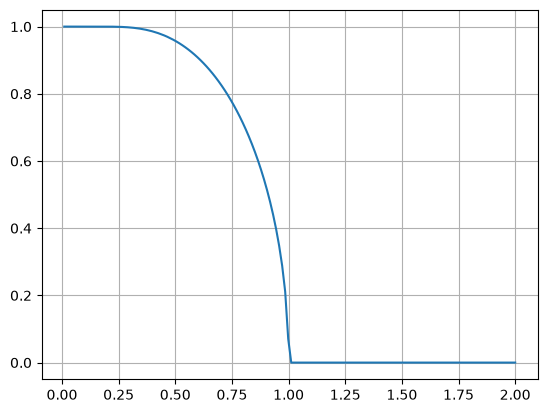

In [67]:
T = np.linspace(0.01,2,150)
M = []
E = []

for t in T: #se realiza la cuenta para cada T. Intenté hacerlo con arrays, no funcionó.
    m_n = 1
    e = 1
    while e > 1e-5:
        mn1 = m_n
        m_n = f(m_n,t)
        e = Exc(m_n,mn1,Df)
    M.append(m_n)
    E.append(e)

plt.plot(T,M)
plt.grid()

## Ceros de una Función

El método anterior también puede trabajarse con el siguiente enfoque. Definimos $g(x) = f(x)-x$, con esto, el problema se reduce a buscar los valores de $x$ donde $g(x) = 0$. Una primera estrategia es utilizar un famoso teorema para funciones continuas: __El teorema de Bolzano__

Dice así: si $f$ es una función continua en un intervalo cerrado $[a,b]$ y se cumple $f(a)f(b)<0$, entonces existe al menos un $c \in [a,b]$ tal que $f(c)=0$.

Es la base del **Método de Bisección**. En resumen, buscaremos con algo de suerte un intervalo $[a,b]$ donde se cumpla este teorema, y para encontrar $c$ reduciremos el tamaño del intervalo hasta que esa c aparezca naturalmente.

Otro método es el de **Newton-Rhapson**. Consiste en partir de la función $g(x)$ en un punto cualquiera $x_n$, y calcular su derivada $g'(x_n)$. Se utiliza esto para construir una recta tangente en el punto, de donde se extrae el punto donde corta el eje horizontal (su cero) $x_1$. Por supuesto, este cero no es el cero de $g(x)$, pero puede ayudarnos a encontrarlo: la distancia entre estos dos puntos se puede dar como $\Delta x = x_0-x_1$, misma diferencia que con la derivada se relaciona como $\Delta x = \frac{f(x_0)}{f'(x_0)}$.

El truco está en que haciendo esto muchas veces, cuando $\Delta x \rightarrow 0$, el cero enésimo $x_n$ tiende al cero de la función $g(x)$. Hace falta ver la prueba, pero se puede llegar a:

$x_{n+1} = x_n - \frac{f(x_n)}{f'(x_n)}$

Reto: programar ambos métodos sin antes haberlos visto en clase

Intento de programación del método de Newton Rhapson. La ecuación objetivo es $f(x)=x-tanh(x)$

In [66]:
import numpy as np

def f(x):
    return x - np.tanh(x)

def df(x):
    return 1 - np.cosh(x)**(-2) #derivada analítica. NO usar la derivada numérica (ni siquiera sé por qué la elegí en primer lugar wwww)

In [68]:
x = 1 #punto de inicio
N = 40 #iteraciones

for i in range(N):
    
    x = x - f(x)/df(x) #fórmula
    
print(x)

7.274473197150702e-08


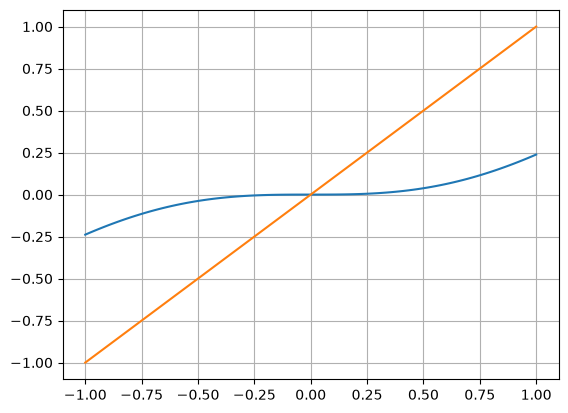

In [51]:
import matplotlib.pyplot as plt

x = np.linspace(-1,1,100)

plt.plot(x,f(x))
plt.plot(x,x)
plt.grid()

Procedemos a calcular el error de este método expandiendo en serie de Taylor alrededor del cero $x^*$:

$f(x) = f(x^*) + (x-x^*)f'(x^*) + \frac{1}{2}(x-x^*)^2f''(x^*)+ \cdots$, pero $f(x^*)=0$

$f(x) =(x-x^*)f'(x^*) + \frac{1}{2}(x-x^*)^2f''(x^*)+ \cdots$, dividimos por $f'(x)$ **Nota: me perdí desde aquí**

$f(x)/f'(x) = x - x^* + \frac{1}{2}(x-x^*)^2f''(x)/f'(x)+ \cdots$. Sumando $x^* - x$

$f(x)/f'(x) - x + x^* = \frac{1}{2}(x-x^*)^2f''(x)/f'(x)+ \cdots$. Identificamos el término enésimo.

$x^* - x_n = \frac{1}{2}(x-x^*)^2f''(x)/f'(x)+ \cdots$

Definimos: $x* = x_n+ \epsilon_n \rightarrow \epsilon_n = x^* - x_n$.

Sustituimos:

$\epsilon_n = \frac{1}{2}(x-x^*)^2f''(x)/f'(x)+ \cdots$

No sé, me perdí. El resultado final es:

$\epsilon_{n+1} = -\frac{1}{2}\frac{f''(x_n)}{f'(x_n)}\epsilon_n^2$

y se cumplirá:

$\epsilon_n \simeq x_{n+1}-x_n$



In [75]:
#experimento

import numpy as np

def f(x):
    return x - np.sin(x)

def df(x):
    return 1 - np.cos(x)

x = 3 #punto de inicio
error = 1

while error > 1e-6:

    x1 = x #término anterior
    
    x = x - f(x)/df(x) #fórmula

    error = x1-x #error
    
print(x)

1.4929826357730905e-06


**Aplicación: obtención de máximos y mínimos de una función**

Como bien sabemos, los mínimos y máximos de una función son puntos en los que su derivada se anula, i. e. $f'(x) = 0$, que es justo lo que hemos estado haciendo en la sección anterior, calcular ceros de funciones. Nótese que al usar Newton-Rhampson, el resultado es inmediato, pues basta con usar las derivadas de la función, la segunda derivada en concreto:

$x_{n+1} = x_n + \frac{f'(x)}{f''(x)}$

Así, $x_n$ sería un punto crítico de la función $f(x)$. Uno luego puede usar la segunda derivada (que ya habremos calculado para este punto) y evaluarla en $x_{n+1}$ para observar si es un máximo, un mínimo o un punto de inflexión.

Más aun, puede generalizarse a varias dimensiones:

$\bar{x}_{n+1} = \bar{x}_n - \gamma \nabla f(x_n)$, con $\gamma = \frac{1}{\nabla^2 f(x_n)}$. Este método lleva el nombre de **gradiente decendente**.